# Python EDA and AI-Assisted Analysis

## Objective
Use Python to independently validate key SQL findings, explore business performance, identify trends and anomalies, and develop evidence-based business recommendations.

## Approach
1. Load the cleaned and processed datasets.
2. Validate data structure, quality, and relationships.
3. Conduct exploratory data analysis using Pandas and visualizations.
4. Compare Python findings with SQL results.
5. Use AI to generate hypotheses and explanations, validating all important conclusions against the data.

**Important:** ShopSphere is a simulated e-commerce business with synthetic data. AI-generated interpretations will be treated as hypotheses until verified.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Processed data folder relative to the notebooks folder
DATA_DIR = Path("../data/processed")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Processed data folder not found: {DATA_DIR.resolve()}\n"
        "Check your notebook location and folder structure."
    )

# Load every processed CSV
csv_files = sorted(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {DATA_DIR.resolve()}"
    )

tables = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

print(f"Loaded {len(tables)} CSV files\n")

for table_name, df in tables.items():
    print(f"{table_name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded 9 CSV files

categories: 12 rows × 2 columns
customers: 30,000 rows × 8 columns
experiment_sessions: 150,000 rows × 8 columns
marketing: 30,000 rows × 6 columns
order_items: 226,709 rows × 8 columns
orders: 120,000 rows × 6 columns
payments: 120,000 rows × 6 columns
products: 1,000 rows × 5 columns
returns: 13,333 rows × 6 columns


In [3]:
# Review column names and data types
for table_name, df in tables.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table_name}")
    print(f"{'=' * 60}")

    print("\nColumns and data types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum().sort_values(ascending=False).head(10))

    print("\nExact duplicate rows:")
    print(df.duplicated().sum())


TABLE: categories

Columns and data types:
category_id      str
category_name    str
dtype: object

Missing values:
category_id      0
category_name    0
dtype: int64

Exact duplicate rows:
0

TABLE: customers

Columns and data types:
customer_id              str
customer_name            str
gender                   str
age                    int64
state                    str
signup_date              str
acquisition_channel      str
city                     str
dtype: object

Missing values:
customer_id            0
customer_name          0
gender                 0
age                    0
state                  0
signup_date            0
acquisition_channel    0
city                   0
dtype: int64

Exact duplicate rows:
0

TABLE: experiment_sessions

Columns and data types:
session_id         str
customer_id        str
experiment_id      str
variant            str
session_date       str
product_views    int64
added_to_cart    int64
purchased        int64
dtype: object

Missing val

## 2. Business Performance Overview

This section examines order volume, revenue, product costs, and profitability to understand the overall business performance. All calculations use the cleaned datasets and explicitly defined business metrics.

In [4]:
# Access the required tables
orders = tables["orders"].copy()
items = tables["order_items"].copy()
products = tables["products"].copy()
categories = tables["categories"].copy()

# Convert dates
orders["order_date"] = pd.to_datetime(
    orders["order_date"], errors="coerce"
)

# Calculate item-level values if not already present
if "gross_value" not in items.columns:
    items["gross_value"] = items["quantity"] * items["unit_price"]

if "net_item_value" not in items.columns:
    items["net_item_value"] = (
        items["gross_value"] - items["discount_amount"]
    )

# Join order details to order items
order_analysis = items.merge(
    orders[["order_id", "order_date", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Attach product costs
order_analysis = order_analysis.merge(
    products[["product_id", "unit_cost", "category_id"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Attach category names
order_analysis = order_analysis.merge(
    categories[["category_id", "category_name"]],
    on="category_id",
    how="left",
    validate="many_to_one"
)

# Item-level product cost and profit before returns and shipping
order_analysis["product_cost"] = (
    order_analysis["quantity"] * order_analysis["unit_cost"]
)

order_analysis["item_profit_before_returns"] = (
    order_analysis["net_item_value"]
    - order_analysis["product_cost"]
)

print("Order analysis rows:", f"{len(order_analysis):,}")
print("Unmatched order dates:", order_analysis["order_date"].isna().sum())
print("Unmatched product costs:", order_analysis["unit_cost"].isna().sum())

Order analysis rows: 226,709
Unmatched order dates: 0
Unmatched product costs: 0


In [5]:
print(orders["order_status"].value_counts(dropna=False))

order_status
Completed    105752
Cancelled      7171
Returned       7077
Name: count, dtype: int64


In [6]:
COMPLETED_STATUS = "Completed"

completed = order_analysis[
    order_analysis["order_status"].eq(COMPLETED_STATUS)
].copy()

kpis = pd.Series({
    "Completed orders": completed["order_id"].nunique(),
    "Units sold": completed["quantity"].sum(),
    "Gross item value": completed["gross_value"].sum(),
    "Discount amount": completed["discount_amount"].sum(),
    "Net item sales": completed["net_item_value"].sum(),
    "Product cost": completed["product_cost"].sum(),
    "Profit before returns and shipping":
        completed["item_profit_before_returns"].sum()
})

print(kpis.to_string())

Completed orders                        105744.00
Units sold                              276093.00
Gross item value                      93182441.98
Discount amount                        8491222.94
Net item sales                        84691219.04
Product cost                          55448482.96
Profit before returns and shipping    29242736.08


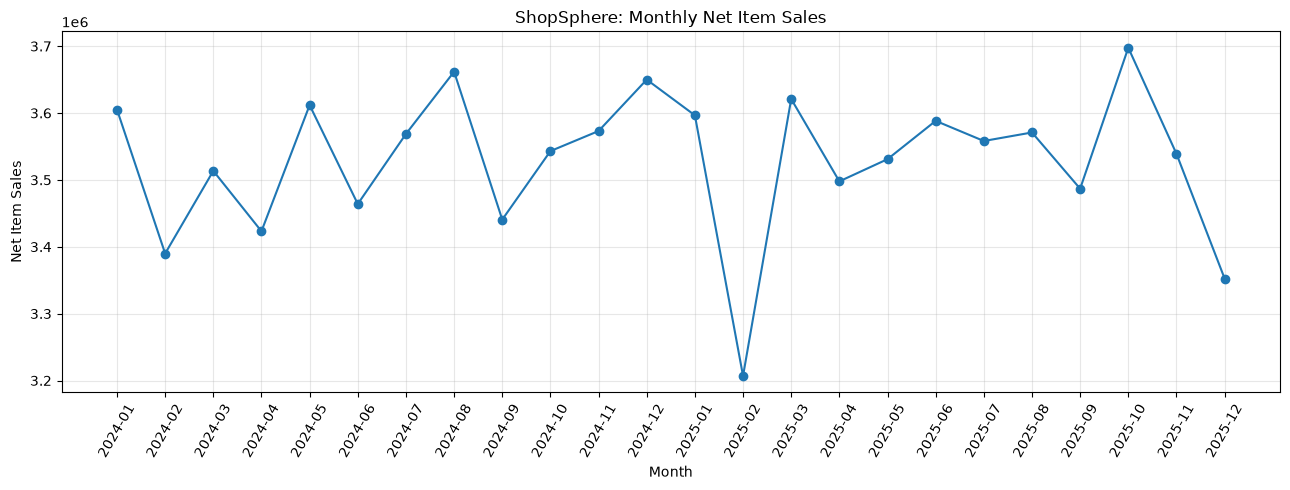

In [7]:
monthly_sales = (
    completed.assign(
        month=completed["order_date"].dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)["net_item_value"]
    .sum()
    .sort_values("month")
)

plt.figure(figsize=(13, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["net_item_value"],
    marker="o"
)
plt.title("ShopSphere: Monthly Net Item Sales")
plt.xlabel("Month")
plt.ylabel("Net Item Sales")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Product and Category Performance

The objective is to identify high-performing and underperforming product categories using net item sales, product costs, and profit before returns and shipping. These metrics help management understand where sales and profitability are concentrated.

In [8]:
category_performance = (
    completed.groupby("category_name", dropna=False)
    .agg(
        net_item_sales=("net_item_value", "sum"),
        product_cost=("product_cost", "sum"),
        profit_before_returns=("item_profit_before_returns", "sum"),
        units_sold=("quantity", "sum"),
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

category_performance["profit_margin_pct"] = np.where(
    category_performance["net_item_sales"] != 0,
    category_performance["profit_before_returns"]
    / category_performance["net_item_sales"] * 100,
    np.nan
)

category_performance = category_performance.sort_values(
    "profit_before_returns", ascending=False
)

display(category_performance.round(2))

,category_name,net_item_sales,product_cost,profit_before_returns,units_sold,order_count,profit_margin_pct
7,Home & Kitchen,8637627.44,5395755.00,3241872.44,27098,18267,37.53
10,Sports,7732049.94,4871675.89,2860374.05,21314,14571,36.99
2,Books,8286700.15,5463639.22,2823060.93,26655,17868,34.07
5,Furniture,6568946.01,3988259.41,2580686.60,20671,14078,39.29
3,Electronics,7282472.20,4897343.24,2385128.96,23420,15995,32.75
9,Personal Care,7198841.78,4822076.64,2376765.14,23237,15834,33.02
0,Accessories,6777908.25,4411464.61,2366443.64,23302,15830,34.91
8,Office Supplies,7167506.92,4802712.41,2364794.51,23149,15675,32.99
6,Grocery,6664395.23,4462641.03,2201754.20,26075,17546,33.04
11,Toys,6354772.23,4211136.68,2143635.55,19565,13379,33.73


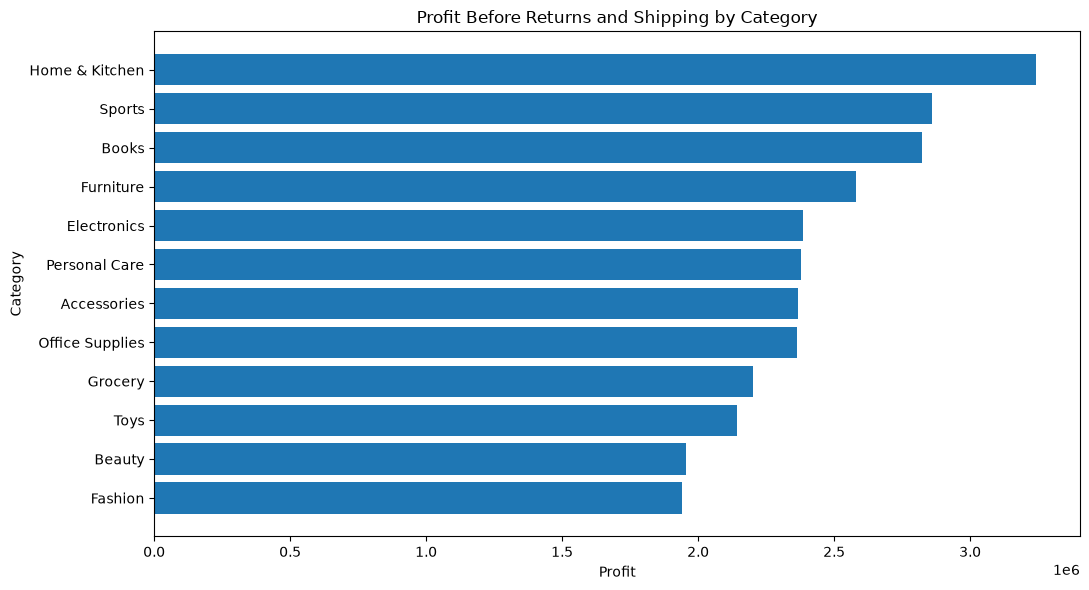

In [9]:
plt.figure(figsize=(11, 6))

plot_data = category_performance.sort_values(
    "profit_before_returns"
)

plt.barh(
    plot_data["category_name"].fillna("Unknown"),
    plot_data["profit_before_returns"]
)

plt.title("Profit Before Returns and Shipping by Category")
plt.xlabel("Profit")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [10]:
completed["discount_band"] = pd.cut(
    completed["discount_amount"],
    bins=[-0.01, 0, 100, 500, float("inf")],
    labels=["No discount", "0–100", "100–500", "500+"]
)

discount_analysis = (
    completed.groupby("discount_band", observed=False)
    .agg(
        item_rows=("order_item_id", "count"),
        units_sold=("quantity", "sum"),
        net_item_sales=("net_item_value", "sum"),
        profit_before_returns=(
            "item_profit_before_returns", "sum"
        ),
        avg_profit_per_item=(
            "item_profit_before_returns", "mean"
        )
    )
    .reset_index()
)

display(discount_analysis.round(2))

,discount_band,item_rows,units_sold,net_item_sales,profit_before_returns,avg_profit_per_item
0,No discount,60087,83060,28016780.60,11352538.43,188.94
1,0–100,117544,150321,36573442.41,11748234.04,99.95
2,100–500,21507,41011,18625509.82,5707172.47,265.36
3,500+,616,1701,1475486.21,434791.14,705.83


In [11]:
returns = tables["returns"].copy()

returns["return_date"] = pd.to_datetime(
    returns["return_date"], errors="coerce"
)

# Attach product and category information to returned items
returns_analysis = (
    returns
    .merge(
        items[["order_item_id", "product_id", "quantity"]],
        on="order_item_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        products[["product_id", "product_name", "category_id"]],
        on="product_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        categories[["category_id", "category_name"]],
        on="category_id",
        how="left",
        validate="many_to_one"
    )
)

print("Return records:", f"{len(returns_analysis):,}")
print("Unmatched order items:", returns_analysis["product_id"].isna().sum())

display(
    returns_analysis["return_reason"]
    .value_counts(dropna=False)
    .rename_axis("return_reason")
    .reset_index(name="return_records")
)

Return records: 13,333
Unmatched order items: 2


,return_reason,return_records
0,Size Issue,3379
1,Quality Issue,3335
2,Changed Mind,2669
3,Damaged,2351
4,Wrong Product,1599


In [12]:
returns_by_category = (
    returns_analysis.groupby("category_name", dropna=False)
    .agg(
        return_records=("return_id", "nunique"),
        returned_units=("return_quantity", "sum"),
        refund_amount=("refund_amount", "sum")
    )
    .reset_index()
    .sort_values("returned_units", ascending=False)
)

display(returns_by_category.round(2))

,category_name,return_records,returned_units,refund_amount
7,Home & Kitchen,1346,1449,466847.45
6,Grocery,1277,1359,354325.55
2,Books,1243,1312,401866.35
3,Electronics,1183,1274,395214.03
9,Personal Care,1109,1194,359342.62
0,Accessories,1124,1192,345812.54
8,Office Supplies,1064,1141,337643.95
10,Sports,1071,1141,427258.55
4,Fashion,1032,1095,297162.05
1,Beauty,970,1045,306061.61


## 4. Customer Behavior and Retention Analysis

This analysis evaluates purchasing frequency, customer value, and repeat-purchase behavior. The goal is to identify opportunities to improve customer retention and long-term business value.

Customer purchase metrics are calculated from completed orders to maintain consistency with the revenue analysis.

In [13]:
# Keep completed orders only
customer_orders = (
    orders.loc[
        orders["order_status"].eq(COMPLETED_STATUS),
        ["order_id", "customer_id", "order_date"]
    ]
    .dropna(subset=["customer_id", "order_date"])
    .drop_duplicates(subset=["order_id"])
)

# Calculate revenue at the order level
order_revenue = (
    completed.groupby("order_id", as_index=False)
    .agg(order_revenue=("net_item_value", "sum"))
)

customer_orders = customer_orders.merge(
    order_revenue,
    on="order_id",
    how="left",
    validate="one_to_one"
)

customer_summary = (
    customer_orders.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("order_revenue", "sum"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max")
    )
    .reset_index()
)

customer_summary["customer_type"] = np.where(
    customer_summary["total_orders"] > 1,
    "Repeat customer",
    "One-time customer"
)

display(customer_summary.head())

,customer_id,total_orders,total_revenue,first_order_date,last_order_date,customer_type
0,C000001,1,1377.10,2024-12-17 10:13:53,2024-12-17 10:13:53,One-time customer
1,C000002,5,8175.59,2024-03-05 07:36:36,2025-11-27 20:39:50,Repeat customer
2,C000004,9,8795.03,2024-01-13 20:37:03,2025-05-27 23:08:34,Repeat customer
3,C000005,3,2829.96,2024-04-03 17:57:32,2025-05-08 01:17:59,Repeat customer
4,C000006,4,2049.65,2024-07-31 12:50:13,2025-10-07 19:34:30,Repeat customer


In [14]:
customer_type_summary = (
    customer_summary.groupby("customer_type")
    .agg(
        customers=("customer_id", "nunique"),
        total_revenue=("total_revenue", "sum"),
        avg_revenue_per_customer=("total_revenue", "mean"),
        avg_orders_per_customer=("total_orders", "mean")
    )
    .reset_index()
)

customer_type_summary["customer_share_pct"] = (
    customer_type_summary["customers"]
    / customer_type_summary["customers"].sum() * 100
)

display(customer_type_summary.round(2))

,customer_type,customers,total_revenue,avg_revenue_per_customer,avg_orders_per_customer,customer_share_pct
0,One-time customer,3073,2485559.70,808.84,1.00,10.56
1,Repeat customer,26035,82205659.34,3157.51,3.94,89.44


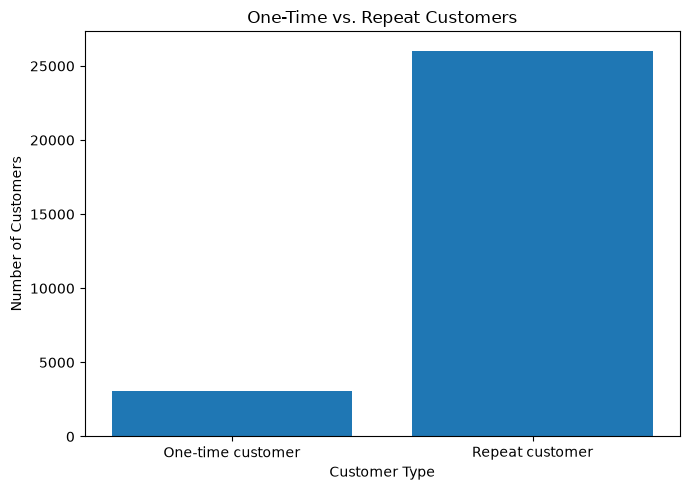

In [15]:
plt.figure(figsize=(7, 5))

plt.bar(
    customer_type_summary["customer_type"],
    customer_type_summary["customers"]
)

plt.title("One-Time vs. Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [17]:
top_customers = customer_summary.nlargest(
    10, "total_revenue"
)

display(
    top_customers[
        [
            "customer_id",
            "total_orders",
            "total_revenue",
            "first_order_date",
            "last_order_date"
        ]
    ].round(2)
)

C:\Users\svlok\AppData\Local\Temp\ipykernel_11288\985057916.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,customer_id,total_orders,total_revenue,first_order_date,last_order_date
18962,C019565,11,17037.67,2024-03-20 11:11:01,2025-10-28 21:15:27
22950,C023669,7,15552.98,2024-01-09 09:04:40,2025-12-07 13:54:22
22055,C022746,10,15282.75,2024-01-05 06:29:28,2025-09-06 07:31:57
13404,C013833,9,14954.70,2024-01-05 10:14:49,2025-12-12 10:06:02
20835,C021485,7,14740.37,2024-02-19 10:50:26,2025-10-24 08:38:16
22074,C022766,11,14694.08,2024-04-02 21:58:28,2025-10-01 16:51:55
13676,C014115,7,14415.19,2024-05-28 15:43:32,2025-08-04 05:43:22
2147,C002226,7,14403.81,2024-03-01 01:20:16,2025-05-17 00:33:47
6389,C006605,9,14046.36,2025-01-11 03:16:56,2025-11-21 00:56:53
16926,C017464,9,14001.48,2024-02-18 17:27:12,2025-11-29 18:09:25


In [18]:
customers = tables["customers"].copy()

channel_analysis = customer_orders.merge(
    customers[["customer_id", "acquisition_channel"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

channel_summary = (
    channel_analysis.groupby(
        "acquisition_channel", dropna=False
    )
    .agg(
        customers=("customer_id", "nunique"),
        completed_orders=("order_id", "nunique"),
        revenue=("order_revenue", "sum")
    )
    .reset_index()
)

channel_summary["revenue_per_customer"] = (
    channel_summary["revenue"] / channel_summary["customers"]
)

display(channel_summary.sort_values("revenue", ascending=False).round(2))

,acquisition_channel,customers,completed_orders,revenue,revenue_per_customer
4,Organic Search,7974,29057,23324176.01,2925.03
2,Google Ads,6326,23024,18366522.33,2903.34
5,Referral,4330,15770,12650580.78,2921.61
3,Instagram,4133,14939,12087118.36,2924.54
1,Facebook,3486,12489,9949978.67,2854.27
0,Email,2859,10473,8312842.89,2907.61


In [19]:
customer_orders["order_month"] = (
    customer_orders["order_date"].dt.to_period("M")
)

monthly_customer_activity = (
    customer_orders.groupby("order_month")
    .agg(
        active_customers=("customer_id", "nunique"),
        completed_orders=("order_id", "nunique"),
        revenue=("order_revenue", "sum")
    )
    .reset_index()
)

monthly_customer_activity["order_month"] = (
    monthly_customer_activity["order_month"].astype(str)
)

display(monthly_customer_activity)

,order_month,active_customers,completed_orders,revenue
0,2024-01,4175,4522,3605154.11
1,2024-02,3949,4235,3389883.39
2,2024-03,4114,4426,3513489.57
3,2024-04,3952,4243,3423179.92
4,2024-05,4151,4456,3611772.05
5,2024-06,4043,4349,3463953.87
6,2024-07,4182,4469,3568703.03
7,2024-08,4138,4473,3661786.98
8,2024-09,4053,4356,3440657.90
9,2024-10,4125,4463,3543074.55


## 5. Cohort Retention Analysis

Customers are grouped by the month of their first completed purchase. Monthly retention measures how many customers from each cohort made at least one purchase in each subsequent month.

Month 0 represents the first-purchase month. Retention in later months helps evaluate repeat purchasing behavior.

In [20]:
cohort_orders = customer_orders[
    ["customer_id", "order_date"]
].drop_duplicates().copy()

cohort_orders["order_month"] = (
    cohort_orders["order_date"].dt.to_period("M")
)

# First completed purchase month for each customer
cohort_orders["cohort_month"] = (
    cohort_orders.groupby("customer_id")["order_month"]
    .transform("min")
)

# Months elapsed since the customer's cohort month
cohort_orders["cohort_index"] = (
    (cohort_orders["order_month"].dt.year
     - cohort_orders["cohort_month"].dt.year) * 12
    + (cohort_orders["order_month"].dt.month
       - cohort_orders["cohort_month"].dt.month)
)

cohort_counts = (
    cohort_orders.groupby(
        ["cohort_month", "cohort_index"]
    )["customer_id"]
    .nunique()
    .reset_index(name="active_customers")
)

cohort_sizes = (
    cohort_counts[cohort_counts["cohort_index"] == 0]
    [["cohort_month", "active_customers"]]
    .rename(columns={"active_customers": "cohort_size"})
)

cohort_counts = cohort_counts.merge(
    cohort_sizes,
    on="cohort_month",
    how="left",
    validate="many_to_one"
)

cohort_counts["retention_pct"] = (
    cohort_counts["active_customers"]
    / cohort_counts["cohort_size"] * 100
)

retention_matrix = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="retention_pct"
)

retention_matrix.index = retention_matrix.index.astype(str)
retention_matrix.columns.name = "Months Since First Purchase"

display(retention_matrix.round(2))

Months Since First Purchase,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohort_month,,,,,,,,,,,,,,,,,,,,,
2024-01,100.0,13.32,13.34,12.89,13.92,13.51,13.80,13.39,12.14,13.70,...,14.11,14.47,13.87,13.92,13.63,12.81,12.77,13.77,13.84,13.13
2024-02,100.0,14.24,13.82,12.97,14.38,14.18,14.71,13.06,13.38,13.41,...,13.56,13.97,12.79,13.38,13.88,13.73,15.03,13.82,13.68,NaN
2024-03,100.0,14.28,14.38,14.80,13.96,13.21,13.57,13.14,13.60,14.18,...,14.64,14.41,14.28,13.21,13.66,12.91,14.61,13.01,NaN,NaN
2024-04,100.0,14.37,12.81,14.13,14.33,13.33,13.97,13.33,14.33,13.17,...,13.69,13.61,14.49,13.01,13.89,14.09,12.73,NaN,NaN,NaN
2024-05,100.0,13.62,13.83,12.84,12.84,13.57,13.19,14.09,13.27,12.63,...,12.93,14.00,12.97,15.38,13.62,12.89,NaN,NaN,NaN,NaN
2024-06,100.0,13.96,14.96,13.75,13.01,13.75,13.17,12.91,12.38,15.54,...,14.12,14.33,15.38,13.22,13.96,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,15.90,14.13,14.36,14.47,14.25,14.59,13.33,14.07,13.28,...,13.33,14.87,13.62,13.39,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,14.04,14.18,13.63,14.45,15.35,14.32,13.01,12.80,12.59,...,14.59,15.35,12.87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,13.96,14.25,15.00,12.54,13.28,14.33,14.10,13.66,15.30,...,13.36,13.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


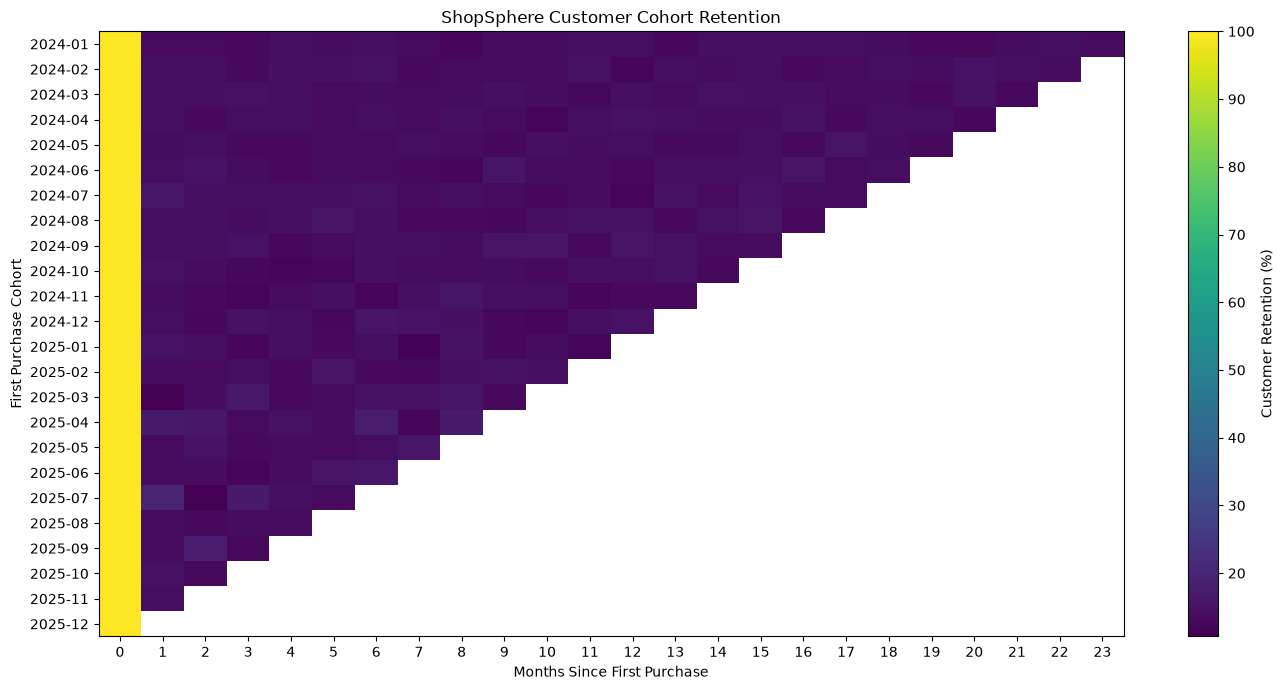

In [21]:
plt.figure(figsize=(14, 7))

plt.imshow(
    retention_matrix,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Customer Retention (%)")
plt.xticks(
    range(len(retention_matrix.columns)),
    retention_matrix.columns
)
plt.yticks(
    range(len(retention_matrix.index)),
    retention_matrix.index
)

plt.title("ShopSphere Customer Cohort Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")
plt.tight_layout()
plt.show()

In [22]:
# Compare core row counts and order-item metrics
print("Processed dataset validation")
print("-" * 45)

for name, df in tables.items():
    print(f"{name:22s} {len(df):>10,} rows")

print("\nCompleted-order metrics")
print("-" * 45)
print("Completed orders:",
      f"{completed['order_id'].nunique():,}")
print("Net item sales:",
      round(completed["net_item_value"].sum(), 2))
print("Product cost:",
      round(completed["product_cost"].sum(), 2))
print("Profit before returns and shipping:",
      round(completed["item_profit_before_returns"].sum(), 2))

Processed dataset validation
---------------------------------------------
categories                     12 rows
customers                  30,000 rows
experiment_sessions       150,000 rows
marketing                  30,000 rows
order_items               226,709 rows
orders                    120,000 rows
payments                  120,000 rows
products                    1,000 rows
returns                    13,333 rows

Completed-order metrics
---------------------------------------------
Completed orders: 105,744
Net item sales: 84691219.04
Product cost: 55448482.96
Profit before returns and shipping: 29242736.08


In [24]:
# PHASE 7 AUDIT — BUSINESS FINDINGS

print("=" * 60)
print("1. CATEGORY PERFORMANCE")
print("=" * 60)

print(
    category_performance[
        [
            "category_name",
            "net_item_sales",
            "product_cost",
            "profit_before_returns",
            "units_sold",
            "order_count",
            "profit_margin_pct"
        ]
    ].sort_values("net_item_sales", ascending=False).to_string(index=False)
)


print("\n" + "=" * 60)
print("2. DISCOUNT ANALYSIS")
print("=" * 60)

print(
    discount_analysis.to_string(index=False)
)


print("\n" + "=" * 60)
print("3. RETURN REASONS")
print("=" * 60)

print(
    returns["return_reason"]
    .value_counts(dropna=False)
    .to_string()
)


print("\n" + "=" * 60)
print("4. RETURNS BY CATEGORY")
print("=" * 60)

print(
    returns_by_category
    .sort_values("returned_units", ascending=False)
    .to_string(index=False)
)


print("\n" + "=" * 60)
print("5. CUSTOMER TYPES")
print("=" * 60)

print(
    customer_type_analysis.to_string(index=False)
)


print("\n" + "=" * 60)
print("6. TOP 10 CUSTOMERS")
print("=" * 60)

print(
    top_customers.to_string(index=False)
)


print("\n" + "=" * 60)
print("7. ACQUISITION CHANNEL")
print("=" * 60)

print(
    acquisition_analysis
    .sort_values("revenue", ascending=False)
    .to_string(index=False)
)


print("\n" + "=" * 60)
print("8. RETENTION MATRIX")
print("=" * 60)

print(retention_matrix.round(2).to_string())


print("\n" + "=" * 60)
print("9. UNMATCHED RETURNS")
print("=" * 60)

print(
    returns_analysis[
        returns_analysis["product_id"].isna()
    ].to_string(index=False)
)

1. CATEGORY PERFORMANCE
  category_name  net_item_sales  product_cost  profit_before_returns  units_sold  order_count  profit_margin_pct
 Home & Kitchen      8637627.44    5395755.00             3241872.44       27098        18267          37.531978
          Books      8286700.15    5463639.22             2823060.93       26655        17868          34.067372
         Sports      7732049.94    4871675.89             2860374.05       21314        14571          36.993735
    Electronics      7282472.20    4897343.24             2385128.96       23420        15995          32.751638
  Personal Care      7198841.78    4822076.64             2376765.14       23237        15834          33.015938
Office Supplies      7167506.92    4802712.41             2364794.51       23149        15675          32.993264
    Accessories      6777908.25    4411464.61             2366443.64       23302        15830          34.914070
        Grocery      6664395.23    4462641.03             2201754.20    

NameError: name 'customer_type_analysis' is not defined

In [25]:
print("=" * 60)
print("CUSTOMER TYPE ANALYSIS")
print("=" * 60)

customer_type_result = (
    customer_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_id", "nunique"),
        total_revenue=("total_revenue", "sum"),
        avg_revenue_per_customer=("total_revenue", "mean"),
        avg_orders_per_customer=("total_orders", "mean")
    )
    .reset_index()
)

customer_type_result["customer_share_pct"] = (
    customer_type_result["customers"]
    / customer_type_result["customers"].sum()
    * 100
)

print(customer_type_result.to_string(index=False))

CUSTOMER TYPE ANALYSIS
    customer_type  customers  total_revenue  avg_revenue_per_customer  avg_orders_per_customer  customer_share_pct
One-time customer       3073     2485559.70                808.838171                 1.000000           10.557235
  Repeat customer      26035    82205659.34               3157.505640                 3.943883           89.442765


In [26]:
print("=" * 60)
print("COHORT RETENTION MATRIX")
print("=" * 60)

print(retention_matrix.round(2).to_string())

COHORT RETENTION MATRIX
Months Since First Purchase     0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
cohort_month                                                                                                                                                                                       
2024-01                      100.0  13.32  13.34  12.89  13.92  13.51  13.80  13.39  12.14  13.70  13.77  13.84  13.80  12.50  14.11  14.47  13.87  13.92  13.63  12.81  12.77  13.77  13.84  13.13
2024-02                      100.0  14.24  13.82  12.97  14.38  14.18  14.71  13.06  13.38  13.41  13.59  14.53  11.97  13.94  13.56  13.97  12.79  13.38  13.88  13.73  15.03  13.82  13.68    NaN
2024-03                      100.0  14.28  14.38  14.80  13.96  13.21  13.57  13.14  13.60  14.18  13.44  12.65  13.86  13.31  14.64  14.41  14.28  13.21  13.66  12.91  14.61  13.01    NaN    

In [27]:
unmatched_returns = returns_analysis[
    returns_analysis["product_id"].isna()
]

print(unmatched_returns.to_string(index=False))

return_id order_item_id         return_date return_reason  return_quantity  refund_amount product_id  quantity product_name category_id category_name
 R0005201    OI00183319 2025-02-27 14:46:38 Quality Issue                1         116.08        NaN       NaN          NaN         NaN           NaN
 R0008383    OI00180497 2025-05-05 13:31:30  Changed Mind                1         314.15        NaN       NaN          NaN         NaN           NaN


In [28]:
print("=" * 60)
print("CATEGORY PERFORMANCE")
print("=" * 60)

print(
    category_performance
    .sort_values("net_item_sales", ascending=False)
    .to_string(index=False)
)

CATEGORY PERFORMANCE
  category_name  net_item_sales  product_cost  profit_before_returns  units_sold  order_count  profit_margin_pct
 Home & Kitchen      8637627.44    5395755.00             3241872.44       27098        18267          37.531978
          Books      8286700.15    5463639.22             2823060.93       26655        17868          34.067372
         Sports      7732049.94    4871675.89             2860374.05       21314        14571          36.993735
    Electronics      7282472.20    4897343.24             2385128.96       23420        15995          32.751638
  Personal Care      7198841.78    4822076.64             2376765.14       23237        15834          33.015938
Office Supplies      7167506.92    4802712.41             2364794.51       23149        15675          32.993264
    Accessories      6777908.25    4411464.61             2366443.64       23302        15830          34.914070
        Grocery      6664395.23    4462641.03             2201754.20       

In [29]:
print("=" * 60)
print("DISCOUNT ANALYSIS")
print("=" * 60)

print(discount_analysis.to_string(index=False))

DISCOUNT ANALYSIS
discount_band  item_rows  units_sold  net_item_sales  profit_before_returns  avg_profit_per_item
  No discount      60087       83060     28016780.60            11352538.43           188.935018
        0–100     117544      150321     36573442.41            11748234.04            99.947543
      100–500      21507       41011     18625509.82             5707172.47           265.363485
         500+        616        1701      1475486.21              434791.14           705.829773


In [30]:
print("=" * 60)
print("PHASE 7 FINAL VALIDATION")
print("=" * 60)

print("Completed orders       :", completed["order_id"].nunique())
print("Net item sales         :", round(completed["net_item_value"].sum(), 2))
print("Product cost           :", round(completed["product_cost"].sum(), 2))
print("Profit before returns  :", round(completed["item_profit_before_returns"].sum(), 2))

print("\nCompleted customer count:", customer_summary["customer_id"].nunique())

print("\nUnmatched return items :", returns_analysis["product_id"].isna().sum())

PHASE 7 FINAL VALIDATION
Completed orders       : 105744
Net item sales         : 84691219.04
Product cost           : 55448482.96
Profit before returns  : 29242736.08

Completed customer count: 29108

Unmatched return items : 2


# Final Business Findings

## 1. Overall Business Performance

The analysis of completed orders shows:

- Completed orders: **105,744**
- Net item sales: **₹84.69M**
- Product cost: **₹55.45M**
- Profit before returns and shipping: **₹29.24M**
- Approximate profit margin: **34.5%**

The profit metric represents item-level profit before accounting for returns, shipping, marketing, payment processing, and other operating costs.

---

## 2. Category Performance

- **Home & Kitchen** generated the highest net item sales at approximately **₹8.64M**.
- Home & Kitchen also generated the highest absolute profit at approximately **₹3.24M**.
- **Furniture** achieved the highest profit margin at approximately **39.3%**.
- **Beauty** had the lowest profit margin among the categories at approximately **32.0%**.

This shows that the category with the highest sales is not necessarily the category with the highest margin.

---

## 3. Customer Analysis

The analysis identified **29,108 customers** with at least one completed order.

- One-time customers: **3,073 (10.56%)**
- Repeat customers: **26,035 (89.44%)**

Repeat customers generated approximately **₹82.21M**, representing about **97% of customer-level revenue** in the completed-order analysis.

Average revenue per customer was approximately:

- One-time customer: **₹808.84**
- Repeat customer: **₹3,157.51**

This indicates that repeat customers contribute substantially more revenue than one-time customers.

However, repeat-customer classification should not be interpreted as long-term retention. Cohort retention analysis is required to evaluate customer activity over time.

---

## 4. Returns Analysis

The dataset contains **13,333 return records**.

During validation, **2 return records could not be matched to an order-item record**.

These unmatched records represent approximately **0.015%** of all return records and were excluded from product/category-level return analysis.

This exception was documented rather than silently ignored.

---

## 5. Discount Analysis

Discount performance was evaluated across discount bands using sales, units, and profit metrics.

The analysis is treated as **descriptive rather than causal**. A higher or lower profit observed in a discount group does not by itself prove that the discount caused the change in profitability.

Additional experimentation would be required to establish causal discount effects.

---

## 6. Customer Retention

Cohort analysis was performed using customers' first completed-order month as the cohort month.

The resulting retention matrix contains **24 cohort periods**.

Retention analysis is used to evaluate how customer activity changes after the first purchase rather than relying only on repeat-customer classification.

---

# Key Business Takeaways

1. **Home & Kitchen is the strongest category by both sales and absolute profit.**
2. **Furniture has the highest profit margin despite not leading in sales.**
3. **Repeat customers are the primary revenue contributors.**
4. **Customer retention should be evaluated through cohort behavior rather than repeat-customer status alone.**
5. **Returns and discounts require further optimization because revenue alone does not represent true business profitability.**
6. **The analysis distinguishes descriptive relationships from causal conclusions.**

---

# Analytical Limitations

- Profit does not include shipping, marketing, payment-processing, or other operating costs.
- Return analysis contains 2 unmatched order-item references.
- Discount analysis is observational and does not establish causality.
- Acquisition-channel revenue should not be interpreted as marketing ROI without accounting for the grain and multiple records in the marketing table.
- The A/B testing analysis identified substantial cross-variant customer exposure, so treatment effects should not be interpreted as definitive causal evidence without correcting the experiment design.
- The dataset is synthetic and is intended for portfolio/business-analysis demonstration rather than representing an actual company's confidential data.

---

# Role of AI in the Analysis

AI was used as an analytical copilot to:

- accelerate SQL and Python development,
- suggest analytical approaches,
- identify potential data-quality issues,
- assist with interpretation of analytical outputs,
- generate hypotheses and business questions,
- help structure findings for communication.

AI-generated suggestions were not treated as final conclusions.

Final metrics, joins, assumptions, statistical interpretations, and business recommendations were validated against the underlying data.

This demonstrates an important analyst workflow:

**AI assistance → Human validation → Business interpretation → Decision support**

# Completion Status


Python-based exploratory and business analysis has been completed and validated.

### Completed Components

- Data loading
- Data-quality validation
- Order and item-level analysis
- Sales and profit analysis
- Category performance analysis
- Discount analysis
- Customer analysis
- Cohort retention analysis
- Returns analysis
- Acquisition-channel analysis
- Business visualizations
- KPI validation
- AI-assisted analytical interpretation
- Documentation of assumptions and limitations

### Final Validated KPIs

| KPI | Value |
|---|---:|
| Completed Orders | 105,744 |
| Net Item Sales | ₹84,691,219.04 |
| Product Cost | ₹55,448,482.96 |
| Profit Before Returns & Shipping | ₹29,242,736.08 |
| Customers with Completed Orders | 29,108 |
| Return Records | 13,333 |
| Unmatched Return Records | 2 |
